<a href="https://colab.research.google.com/github/ganapriyahs/learn_ml_with_me/blob/main/Collaborative_filtering_recommender.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Collaborative Filtering = "People like you also liked..."
#### In this file I walk through my first **recommender system**.

Setup: users rate movies (0.5 to 5 stars), but each user has only rated a small fraction of all movies. The job is to **predict the missing ratings** and recommend the movies with the highest predicted rating.

The key idea of collaborative filtering: I do **not** tell the model anything about the movies (genre, actor, ...). It *learns* a short feature vector $x^{(i)}$ for every movie and a parameter vector $w^{(j)}$ for every user, such that

$$\hat y^{(i,j)} = w^{(j)}\cdot x^{(i)} + b^{(j)}$$

matches the ratings that exist. Those learned movie features end up capturing things like "how action-heavy is this movie" without anyone labeling it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Notation
- `Y[i, j]` = rating movie *i* got from user *j*
- `R[i, j]` = 1 if user *j* rated movie *i*, else 0 (the model must only learn from the ratings that exist!)
- `X` = movie features (num_movies x num_features), `W` = user parameters (num_users x num_features), `b` = user biases (1 x num_users)

## The data
The course uses a real movie dataset. Here I simulate one: every movie and user secretly has 3 hidden tastes, a rating is their dot product plus noise, and only ~35% of the ratings are revealed.

In [2]:
rng = np.random.default_rng(0)
num_movies, num_users, true_k = 80, 30, 3
true_X = rng.normal(0, 1, (num_movies, true_k))
true_W = rng.normal(0, 1, (num_users, true_k))
full = np.clip(np.round((3 + 0.9 * true_X @ true_W.T + rng.normal(0, 0.3, (num_movies, num_users))) * 2) / 2, 0.5, 5)

R = (rng.random((num_movies, num_users)) < 0.35).astype(float)      # which ratings we get to see
Y = full * R
# hold out 15% of the *observed* ratings to test on
test_mask = (rng.random(R.shape) < 0.15) & (R == 1)
R_train = R * (~test_mask); Y_train = Y * R_train
print("movies x users:", Y.shape)
print("observed ratings:", int(R.sum()), "| used for training:", int(R_train.sum()), "| held out:", int(test_mask.sum()))
print(f"average rating of observed entries: {Y[R == 1].mean():.2f}")

movies x users: (80, 30)
observed ratings: 828 | used for training: 692 | held out: 136
average rating of observed entries: 2.91


## Cost function
Sum the squared error **only where a rating exists** ($r(i,j)=1$), and regularize both $W$ and $X$ so the model does not overfit the few ratings it has:

$$J = \frac{1}{2}\sum_{(i,j):\,r(i,j)=1}\big(w^{(j)}\cdot x^{(i)} + b^{(j)} - y^{(i,j)}\big)^2 + \frac{\lambda}{2}\Big(\sum_{j,k}(w^{(j)}_k)^2 + \sum_{i,k}(x^{(i)}_k)^2\Big)$$

In [3]:
def cofi_cost(X, W, b, Y, R, lambda_):
    err = (X @ W.T + b - Y) * R                    # zero out entries with no rating
    return 0.5 * np.sum(err ** 2) + (lambda_ / 2) * (np.sum(W ** 2) + np.sum(X ** 2))

def cofi_grad(X, W, b, Y, R, lambda_):
    err = (X @ W.T + b - Y) * R
    dX = err @ W + lambda_ * X
    dW = err.T @ X + lambda_ * W
    db = err.sum(axis=0, keepdims=True)
    return dX, dW, db

In the course lab, TensorFlow works out the gradient automatically. I derived it by hand above, so I check it against a numerical estimate before trusting it - a useful habit.

In [4]:
rng = np.random.default_rng(1)
Xc, Wc, bc = rng.normal(size=(6, 3)), rng.normal(size=(4, 3)), rng.normal(size=(1, 4))
Yc = rng.integers(1, 6, (6, 4)).astype(float); Rc = (rng.random((6, 4)) < 0.6).astype(float)
dX, dW, db = cofi_grad(Xc, Wc, bc, Yc, Rc, 1.5)

def numeric(param, which, eps=1e-6):
    g = np.zeros_like(param)
    for idx in np.ndindex(*param.shape):
        old = param[idx]
        param[idx] = old + eps; hi = cofi_cost(Xc, Wc, bc, Yc, Rc, 1.5)
        param[idx] = old - eps; lo = cofi_cost(Xc, Wc, bc, Yc, Rc, 1.5)
        param[idx] = old; g[idx] = (hi - lo) / (2 * eps)
    return g

for name, a, p in [("X", dX, Xc), ("W", dW, Wc), ("b", db, bc)]:
    print(f"max |analytic - numeric| for {name}: {np.abs(a - numeric(p, name)).max():.2e}")

max |analytic - numeric| for X: 5.71e-09
max |analytic - numeric| for W: 6.28e-09
max |analytic - numeric| for b: 5.65e-10


## Mean normalization
A user who rated nothing would get predictions of 0 stars (all their weights are pulled to 0 by regularization). Better: subtract each **movie's average rating** before training and add it back when predicting, so a brand-new user starts out with "the average opinion" instead of zero.

In [5]:
def normalize_ratings(Y, R):
    mu = (Y * R).sum(axis=1) / np.maximum(R.sum(axis=1), 1)       # per-movie mean over rated entries only
    return (Y - mu[:, None]) * R, mu

Ynorm, Ymean = normalize_ratings(Y_train, R_train)
print("first movie mean rating:", Ymean[0].round(2))

first movie mean rating: 3.17


## Learn the parameters
I use plain gradient descent with an **Adam**-style update (the same optimizer the lab uses through `tf.keras.optimizers.Adam`). Initial values are small random numbers - not zeros - so that the features can differentiate from each other.

iteration    1: cost 521.77
iteration  100: cost 112.89
iteration  200: cost 112.06
iteration  300: cost 111.80
iteration  400: cost 111.79


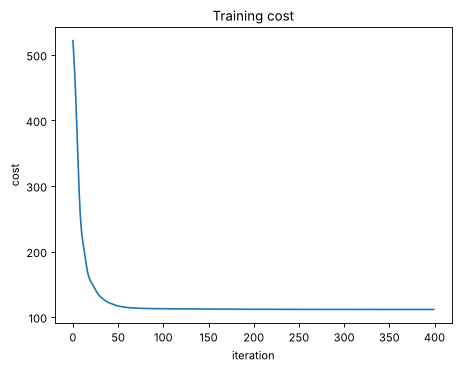

In [6]:
def adam_train(Ynorm, R, num_features=10, lambda_=1.0, lr=0.05, iters=400, seed=1, verbose=True):
    rng = np.random.default_rng(seed)
    n_m, n_u = Ynorm.shape
    params = [0.1 * rng.normal(size=(n_m, num_features)), 0.1 * rng.normal(size=(n_u, num_features)), np.zeros((1, n_u))]
    m = [np.zeros_like(p) for p in params]; v = [np.zeros_like(p) for p in params]
    history = []
    for t in range(1, iters + 1):
        grads = cofi_grad(*params, Ynorm, R, lambda_)
        for k in range(3):
            m[k] = 0.9 * m[k] + 0.1 * grads[k]
            v[k] = 0.999 * v[k] + 0.001 * grads[k] ** 2
            params[k] -= lr * (m[k] / (1 - 0.9 ** t)) / (np.sqrt(v[k] / (1 - 0.999 ** t)) + 1e-8)
        history.append(cofi_cost(*params, Ynorm, R, lambda_))
        if verbose and (t % 100 == 0 or t == 1):
            print(f"iteration {t:4}: cost {history[-1]:.2f}")
    return params, history

(X_hat, W_hat, b_hat), J_hist = adam_train(Ynorm, R_train)
plt.plot(J_hist); plt.xlabel("iteration"); plt.ylabel("cost"); plt.title("Training cost"); plt.show()

## Is it any good? Compare with a naive baseline on ratings it never saw
Baseline: predict every held-out rating as that movie's average. If collaborative filtering cannot beat that, it is not learning anything about *individual* taste.

In [7]:
pred = X_hat @ W_hat.T + b_hat + Ymean[:, None]
rmse = lambda p: np.sqrt(np.mean((p[test_mask] - Y[test_mask]) ** 2))
baseline = np.repeat(Ymean[:, None], num_users, axis=1)
print(f"held-out RMSE, movie-average baseline : {rmse(baseline):.3f}")
print(f"held-out RMSE, collaborative filtering: {rmse(np.clip(pred, 0.5, 5)):.3f}")

held-out RMSE, movie-average baseline : 1.325
held-out RMSE, collaborative filtering: 0.926


## Recommend movies
For one user: predict a rating for every movie they have **not** rated, sort, show the top ones.

In [8]:
user = 4
unseen = np.where(R[:, user] == 0)[0]                         # movies this user never rated
top = unseen[np.argsort(-pred[unseen, user])][:5]
print(f"Top 5 recommendations for user {user}:")
for i in top:
    print(f"  movie {i:2d}: predicted {np.clip(pred[i, user], 0.5, 5):.2f} stars   (true hidden rating: {full[i, user]})")

Top 5 recommendations for user 4:
  movie 73: predicted 4.93 stars   (true hidden rating: 4.5)
  movie 63: predicted 4.61 stars   (true hidden rating: 2.5)
  movie 65: predicted 4.54 stars   (true hidden rating: 5.0)
  movie  2: predicted 4.50 stars   (true hidden rating: 3.0)
  movie  7: predicted 4.42 stars   (true hidden rating: 5.0)


## Finding related items
Because every movie now has a learned feature vector $x^{(i)}$, "similar movies" are just movies with a small squared distance $\lVert x^{(k)}-x^{(i)}\rVert^2$ between their vectors.

In [9]:
def similar_to(i, k=4):
    d = np.sum((X_hat - X_hat[i]) ** 2, axis=1)
    d[i] = np.inf
    return np.argsort(d)[:k]

i = 10
print("movies closest to movie", i, ":", similar_to(i))
print("correlation of their TRUE taste vectors with movie 10's (higher = more alike):")
for j in similar_to(i):
    print(f"  movie {j}: {np.corrcoef(true_X[i], true_X[j])[0, 1]:+.2f}")

movies closest to movie 10 : [37 31 12 50]
correlation of their TRUE taste vectors with movie 10's (higher = more alike):
  movie 37: -0.14
  movie 31: +0.92
  movie 12: +0.81
  movie 50: -0.17


It is a mixed result: some neighbours are genuinely alike and some are not. That is expected - each movie here has only about ten ratings, so its learned vector is noisy. With more ratings per movie the neighbours get better.

## Drawbacks / things to remember
- **Cold start**: a new movie with no ratings, or a new user with none, gives the model nothing to learn from (mean normalization only helps a bit). This is where *content-based* filtering (next notebook) is stronger.
- **Learned features are not interpretable** - the numbers have no names, even if they correspond to taste.
- **Needs lots of overlap** between users and items; with very sparse ratings it overfits (so regularization is important).
- **No side information** - it can't use genre, age, price, etc. even when they are available.
- It never explains *why* something was recommended, and it can create feedback loops (popular things get recommended -> get more ratings).